# 01 — Exploration des données

Objectif : comprendre le dataset **avant toute modélisation**.

1. Vue d'ensemble (schéma, valeurs manquantes, colonnes inutiles)
2. Unicité & **data leakage** (doublons exacts et quasi-doublons)
3. Distribution des **labels** (déséquilibre, cardinalité, co-occurrences)
4. Distributions des textes / code / métadonnées et **outliers**
5. Synthèse des décisions pour la suite

> Aucun modèle ici : uniquement de l'analyse.

In [1]:
import re
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.sparse.csgraph import connected_components
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.config import RAW_DATASET_DIR, TARGET_TAGS
from src.data import download_dataset, load_raw_dataset

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 120)

In [2]:
if not RAW_DATASET_DIR.exists():
    download_dataset()

df = load_raw_dataset()
print(df.shape)
df.head(3)

(4982, 21)


,prob_desc_time_limit,prob_desc_sample_outputs,src_uid,prob_desc_notes,prob_desc_description,prob_desc_output_spec,prob_desc_input_spec,prob_desc_output_to,prob_desc_input_from,lang,...,difficulty,file_name,code_uid,prob_desc_memory_limit,prob_desc_sample_inputs,exec_outcome,source_code,prob_desc_created_at,tags,hidden_unit_tests
sample_id,,,,,,,,,,,,,,,,,,,,,
0,2 seconds,"[""2\n2 4\n3 3\n3 1""]",591372383cf3624f69793c41370022de,NaN,"Numbers $$$1, 2, 3, \dots n$$$ (each integer from $$$1$$$ to $$$n$$$ once) are written on a board. In one operation ...","For each test case, in the first line, print the minimum possible number left on the board after $$$n - 1$$$ operati...",The first line contains one integer $$$t$$$ ($$$1 \le t \le 1000$$$) — the number of test cases. The only line of ea...,standard output,standard input,Python 3,...,1000.0,train_000.jsonl,88084dde61bbebdebe163309a2bda179,256 megabytes,"[""1\n4""]",PASSED,"\ndef ii(): return int(input())\ndef mi(): return map(int, input().split())\n\n\nif __name__ == '__main__':\n for...",1602407100,"[greedy, constructive algorithms, math, implementation, data structures]",
1,3 seconds,"[""4\n10\n4\n0""]",afcd41492158e68095b01ff1e88c3dd4,"NoteIn the first test case of the example, the optimal sequence of moves can be as follows: before making moves $$$...","There are $$$n$$$ positive integers $$$a_1, a_2, \dots, a_n$$$. For the one move you can choose any even value $$$c$...",For $$$t$$$ test cases print the answers in the order of test cases in the input. The answer for the test case is th...,The first line of the input contains one integer $$$t$$$ ($$$1 \le t \le 10^4$$$) — the number of test cases in the ...,standard output,standard input,Python 3,...,1200.0,train_000.jsonl,df0e2ae03513f2b9280e19a1df6c8d84,256 megabytes,"[""4\n6\n40 6 40 3 20 1\n1\n1024\n4\n2 4 8 16\n3\n3 1 7""]",PASSED,"a = int(input())\nfor i in range(a):\n f = int(input())\n k = list(map(int, input().split()))\n l = set()\n...",1576321500,"[number theory, greedy]",
2,2 seconds,"[""0\n1\n2\n0""]",d0c50562764f2008045fe57e5da5de1c,NaN,You are playing a game where your character should overcome different obstacles. The current problem is to come down...,For each query print one integer — the minimum number of magic crystals you have to spend to safely come down on the...,The first line contains one integer $$$q$$$ ($$$1 \le q \le 100$$$) — the number of queries. Each query contains two...,standard output,standard input,PyPy 2,...,1600.0,train_000.jsonl,b084f1988c923dff4a8b4fa95dc6f846,256 megabytes,"[""4\n3 2\n3 1\n8 6\n8 7 6 5 3 2\n9 6\n9 8 5 4 3 1\n1 1\n1""]",PASSED,"#!/usr/bin/env pypy\nfrom __future__ import division, print_function\nfrom collections import defaultdict, Counter, ...",1570545300,"[dp, greedy, math]",


## 1. Vue d'ensemble

In [3]:
overview = pd.DataFrame(
    {
        "dtype": df.dtypes.astype(str),
        "n_missing": df.isna().sum(),
        "pct_missing": (df.isna().mean() * 100).round(1),
        "n_unique": df.apply(lambda s: s.astype(str).nunique()),
    }
).sort_values("n_missing", ascending=False)
overview

,dtype,n_missing,pct_missing,n_unique
prob_desc_notes,object,1350,27.1,3597
prob_desc_output_spec,object,85,1.7,4822
difficulty,float64,39,0.8,30
prob_desc_input_spec,object,33,0.7,4928
prob_desc_output_to,object,1,0.0,4
prob_desc_input_from,object,1,0.0,4
prob_desc_time_limit,object,0,0.0,22
prob_desc_memory_limit,object,0,0.0,17
tags,object,0,0.0,1907
prob_desc_created_at,object,0,0.0,1156


In [4]:
# Colonnes constantes ou vides : aucune information exploitable
constant_cols = [c for c in df.columns if df[c].astype(str).nunique() <= 1]
print("Colonnes constantes :", constant_cols)
print("hidden_unit_tests non vides :", (df["hidden_unit_tests"].str.len() > 0).sum())

Colonnes constantes : ['lang_cluster', 'exec_outcome', 'hidden_unit_tests']
hidden_unit_tests non vides : 0


In [5]:
for col in ["lang", "prob_desc_input_from", "prob_desc_output_to", "prob_desc_memory_limit"]:
    print(df[col].value_counts(dropna=False).head(8), end="\n\n")

lang
Python 3     2089
PyPy 3        935
PyPy 3-64     716
PyPy 2        654
Python 2      588
Name: count, dtype: int64

prob_desc_input_from
standard input      4933
input.txt             32
стандартный ввод      16
NaN                    1
Name: count, dtype: int64

prob_desc_output_to
standard output      4933
output.txt             32
стандартный вывод      16
NaN                     1
Name: count, dtype: int64

prob_desc_memory_limit
256 megabytes     4521
512 megabytes      347
64 megabytes        61
1024 megabytes      15
256 мегабайт        12
128 megabytes        9
512 мегабайт         5
265 megabytes        2
Name: count, dtype: int64



**Constats**
- 4 982 lignes, 21 colonnes ; `lang_cluster`, `exec_outcome` sont constantes et `hidden_unit_tests` est vide → à ignorer.
- `prob_desc_notes` manque dans ~27 % des cas, `difficulty` dans 39 cas : pas bloquant, à gérer (chaîne vide / imputation).
- Quelques métadonnées sont en **russe** (`мегабайт`, `стандартный ввод`) → normalisation nécessaire si on les parse.
- `lang` mélange **Python 2 et 3** : un parsing `ast` du code échouera sur une partie des solutions (prévoir une approche lexicale).

## 2. Unicité & data leakage

Le sujet annonce des exercices *tous différents*. On vérifie les doublons exacts, puis les **quasi-doublons**
(ex. versions *easy / hard* d'un même problème) qui, répartis entre train et test, gonfleraient artificiellement les scores.

In [6]:
for col in ["src_uid", "code_uid", "prob_desc_description", "source_code"]:
    print(f"{col:<25} uniques : {df[col].nunique()} / {len(df)}")

src_uid                   uniques : 4982 / 4982
code_uid                  uniques : 4982 / 4982
prob_desc_description     uniques : 4982 / 4982
source_code               uniques : 4982 / 4982


In [7]:
def near_duplicate_pairs(texts: pd.Series, threshold: float, **tfidf_kwargs) -> pd.DataFrame:
    """Paires (i, j) dont la similarité cosinus TF-IDF dépasse `threshold`."""
    X = TfidfVectorizer(**tfidf_kwargs).fit_transform(texts)
    sim = cosine_similarity(X)
    np.fill_diagonal(sim, 0)
    i, j = np.where(np.triu(sim) > threshold)
    return pd.DataFrame({"i": texts.index[i], "j": texts.index[j], "sim": sim[i, j]})


desc_sim = near_duplicate_pairs(df["prob_desc_description"], threshold=0.5, min_df=2)
thresholds = [0.6, 0.7, 0.8, 0.9, 0.95]
pd.DataFrame(
    {"seuil": thresholds, "n_paires": [(desc_sim["sim"] > t).sum() for t in thresholds]}
)

,seuil,n_paires
0,0.60,794
1,0.70,266
2,0.80,116
3,0.90,75
4,0.95,64


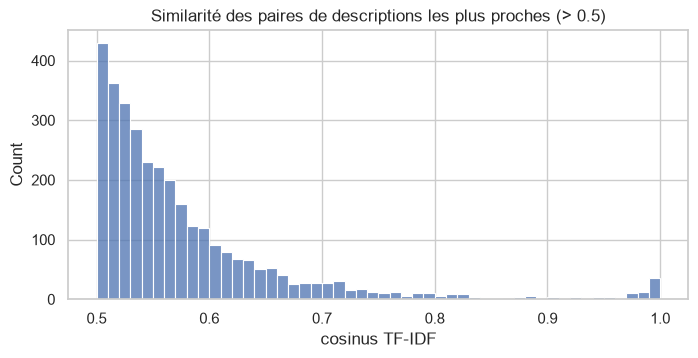

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.histplot(desc_sim.loc[desc_sim["sim"] > 0.5, "sim"], bins=50, ax=ax)
ax.set(title="Similarité des paires de descriptions les plus proches (> 0.5)", xlabel="cosinus TF-IDF")
plt.show()

In [9]:
NEAR_DUP_THRESHOLD = 0.8
pairs = desc_sim[desc_sim["sim"] > NEAR_DUP_THRESHOLD].copy()
target_set = df["tags"].apply(lambda ts: frozenset(ts) & set(TARGET_TAGS))
pairs["same_tags"] = [set(df.at[i, "tags"]) == set(df.at[j, "tags"]) for i, j in zip(pairs["i"], pairs["j"])]
pairs["same_target_tags"] = [target_set[i] == target_set[j] for i, j in zip(pairs["i"], pairs["j"])]
print(f"{len(pairs)} paires > {NEAR_DUP_THRESHOLD}")
print(f"  tags identiques (37 tags)  : {pairs['same_tags'].mean():.0%}")
print(f"  tags cibles identiques (8) : {pairs['same_target_tags'].mean():.0%}")

sample = pairs.sort_values("sim").iloc[[0, len(pairs) // 2, -1]]
for _, row in sample.iterrows():
    print(f"\n--- sim={row.sim:.2f} | tags identiques={row.same_tags}")
    for k in (row.i, row.j):
        print(f"[{k}] {df.at[k, 'tags']}\n    {df.at[k, 'prob_desc_description'][:200]}")

116 paires > 0.8
  tags identiques (37 tags)  : 17%
  tags cibles identiques (8) : 75%

--- sim=0.80 | tags identiques=False
[935] ['implementation', 'greedy']
    Permutation p is an ordered set of integers p1,  p2,  ...,  pn, consisting of n distinct positive integers, each of them doesn't exceed n. We'll denote the i-th element of permutation p as pi. We'll c
[1666] ['implementation', 'sortings', 'greedy']
    Permutation p is an ordered set of integers p1,  p2,  ...,  pn, consisting of n distinct positive integers, each of them doesn't exceed n. We'll denote the i-th element of permutation p as pi. We'll c

--- sim=0.97 | tags identiques=False
[4880] ['dp', 'greedy', 'implementation']
    This is the hard version of the problem. The only difference between the two versions is that the harder version asks additionally for a minimum number of subsegments.Tokitsukaze has a binary string $
[4881] ['implementation']
    This is the easy version of the problem. The only difference betwee

In [10]:
# Regroupement transitif des quasi-doublons : un groupe = un même problème "sous-jacent"
idx_pos = {k: p for p, k in enumerate(df.index)}
adj = np.zeros((len(df), len(df)), dtype=bool)
adj[[idx_pos[i] for i in pairs["i"]], [idx_pos[j] for j in pairs["j"]]] = True
n_groups, labels = connected_components(adj, directed=False)
df["dup_group"] = labels

group_sizes = df["dup_group"].value_counts()
print(f"{(group_sizes > 1).sum()} groupes de quasi-doublons, couvrant {group_sizes[group_sizes > 1].sum()} exercices")
group_sizes[group_sizes > 1].value_counts().rename("n_groupes").rename_axis("taille")

99 groupes de quasi-doublons, couvrant 205 exercices


taille
2    97
6     1
5     1
Name: n_groupes, dtype: int64

In [11]:
code_sim = near_duplicate_pairs(df["source_code"], threshold=0.95, min_df=2, token_pattern=r"\S+")
code_sim["desc_sim"] = code_sim.merge(desc_sim, on=["i", "j"], how="left")["sim_y"].fillna(0).values
print(f"{len(code_sim)} paires de codes quasi identiques (> 0.95)")
print(f"dont descriptions aussi proches (> {NEAR_DUP_THRESHOLD}) : {(code_sim['desc_sim'] > NEAR_DUP_THRESHOLD).sum()}")
# Les autres paires partagent surtout un template d'auteur (fast-IO, imports) sur des problèmes différents
k = code_sim.loc[code_sim["desc_sim"] <= NEAR_DUP_THRESHOLD, "i"].iloc[0]
print(df.at[k, "source_code"][:300])

57 paires de codes quasi identiques (> 0.95)
dont descriptions aussi proches (> 0.8) : 2
#!/usr/bin/env pypy
from __future__ import division, print_function
from collections import defaultdict, Counter, deque
from future_builtins import ascii, filter, hex, map, oct, zip
from itertools import imap as map, izip as zip, permutations, combinations, combinations_with_replacement
from __built


### Fuites via les features

On vérifie qu'aucune colonne ne contient directement la cible, et on mesure à quel point les **noms de tags** apparaissent
littéralement dans le texte (signal légitime, mais à garder en tête : un modèle par mots-clés sera fort sur ces tags).

In [12]:
text_cols = df.select_dtypes("object").columns.drop("tags")
tag_literal = r"(.{0,60}tags?\s*[:=].{0,60})"
for col in text_cols:
    hits = df[col].astype(str).str.extract(tag_literal, flags=re.IGNORECASE)[0].dropna()
    for k, snippet in hits.items():
        print(f"{col} [{k}] : ...{snippet}...")

prob_desc_description [1098] : ... simple regular HTML table in which meet only the following tags : "table", "tr", "td", all the tags are paired and the table ...


In [13]:
KEYWORDS = {
    "math": r"\bmath",
    "graphs": r"\bgraph",
    "strings": r"\bstring",
    "number theory": r"\b(?:prime|gcd|divisor|modulo)",
    "trees": r"\btree",
    "geometry": r"\b(?:polygon|point|circle|angle)",
    "games": r"\b(?:game|player|win)",
    "probabilities": r"\b(?:probabilit|expected)",
}
desc_lower = df["prob_desc_description"].str.lower()
rows = []
for tag, pattern in KEYWORDS.items():
    has_kw = desc_lower.str.contains(pattern, regex=True)
    has_tag = df["tags"].apply(lambda ts, t=tag: t in ts)
    rows.append({"tag": tag, "pattern": pattern, "P(tag | mot-clé)": has_tag[has_kw].mean(), "P(mot-clé | tag)": has_kw[has_tag].mean()})
pd.DataFrame(rows).round(2)

,tag,pattern,P(tag | mot-clé),P(mot-clé | tag)
0,math,\bmath,0.43,0.04
1,graphs,\bgraph,0.60,0.31
2,strings,\bstring,0.50,0.75
3,number theory,\b(?:prime|gcd|divisor|modulo),0.40,0.45
4,trees,\btree,0.71,0.63
5,geometry,\b(?:polygon|point|circle|angle),0.22,0.77
6,games,\b(?:game|player|win),0.15,0.89
7,probabilities,\b(?:probabilit|expected),0.69,0.68


**Constats leakage**
- Aucun doublon exact (`src_uid`, descriptions, codes tous uniques), mais **116 paires de quasi-doublons** (cosinus > 0.8),
  regroupées en 99 groupes / 205 exercices : surtout des versions *easy / hard* d'un même énoncé.
- Ces paires n'ont les mêmes tags que dans 17 % des cas (75 % sur les 8 tags cibles) : un texte quasi identique peut porter
  des labels différents ⇒ **bruit d'annotation** irréductible, et risque de leakage si les deux versions sont séparées.
- ⇒ le split train/val/test devra être **groupé par `dup_group`** (en plus d'être stratifié multi-label).
- Les 57 paires de codes quasi identiques viennent presque toutes d'un même **template d'auteur** (imports, fast-IO) sur des
  problèmes différents : pas une fuite, mais du bruit à retirer côté features de code.
- Aucune colonne ne contient les tags (seul match « tags: » = balises HTML d'un énoncé). Les mots-clés couvrent bien certains
  tags (`games` 89 %, `geometry` 77 %, `strings` 75 %) mais sont peu précis seuls (`games` 15 %) : bonne base pour TF-IDF.
- `math` n'est presque jamais nommé dans l'énoncé (4 %) : tag « conceptuel », probablement le plus dur à capter par mots-clés.

## 3. Distribution des labels

37 tags distincts


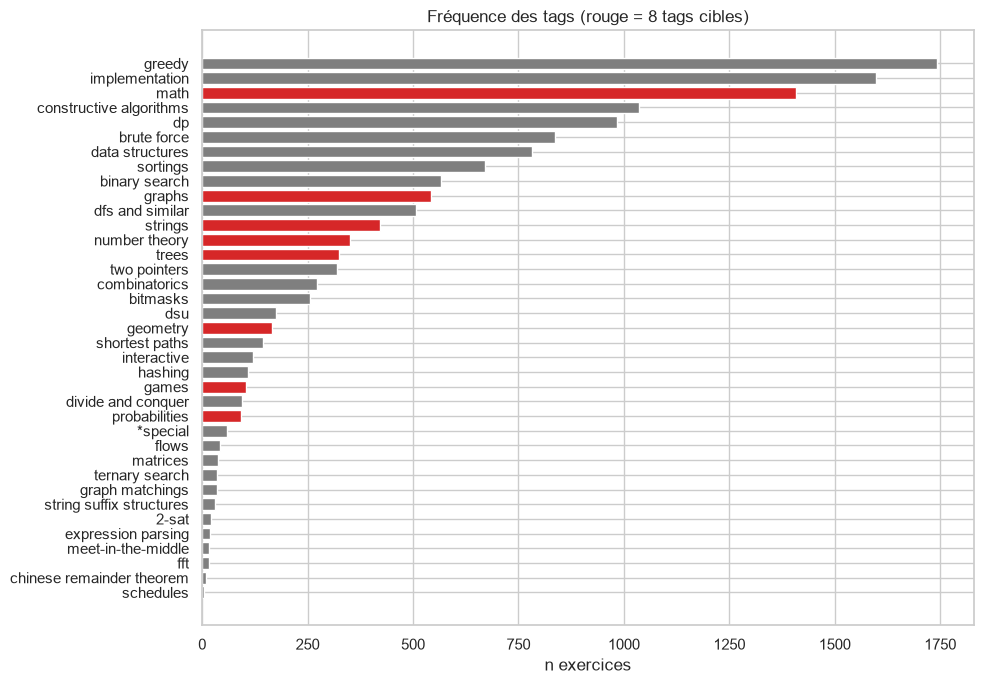

In [14]:
tag_counts = pd.Series(Counter(t for ts in df["tags"] for t in ts)).sort_values(ascending=False)
print(f"{len(tag_counts)} tags distincts")

fig, ax = plt.subplots(figsize=(10, 7))
colors = ["tab:red" if t in TARGET_TAGS else "tab:gray" for t in tag_counts.index]
ax.barh(tag_counts.index[::-1], tag_counts.values[::-1], color=colors[::-1])
ax.set(title="Fréquence des tags (rouge = 8 tags cibles)", xlabel="n exercices")
plt.tight_layout()
plt.show()

In [15]:
target_stats = pd.DataFrame({"n": tag_counts[TARGET_TAGS], "prevalence_%": (tag_counts[TARGET_TAGS] / len(df) * 100).round(1)})
target_stats["ratio_desequilibre"] = (len(df) / target_stats["n"] - 1).round(1)
target_stats

,n,prevalence_%,ratio_desequilibre
math,1409,28.3,2.5
graphs,542,10.9,8.2
strings,422,8.5,10.8
number theory,350,7.0,13.2
trees,324,6.5,14.4
geometry,166,3.3,29.0
games,105,2.1,46.4
probabilities,92,1.8,53.2


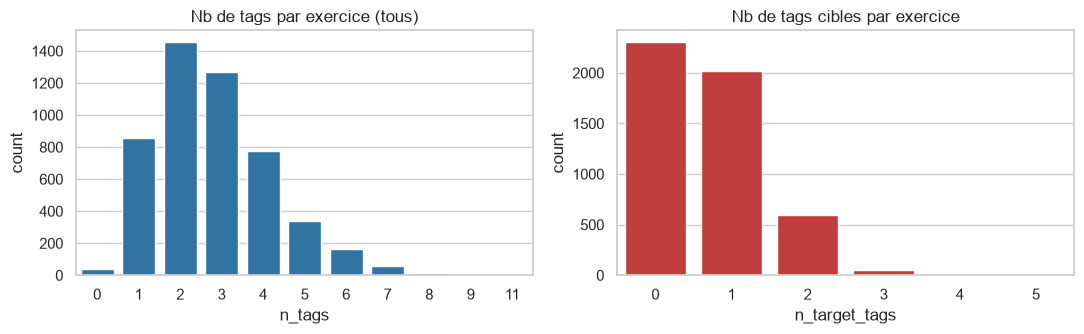

Sans aucun tag : 41
Sans tag cible : 46.2%
Label cardinality (cibles) : 0.68


In [16]:
df["n_tags"] = df["tags"].str.len()
df["n_target_tags"] = df["tags"].apply(lambda ts: sum(t in TARGET_TAGS for t in ts))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.countplot(x=df["n_tags"], ax=axes[0], color="tab:blue").set(title="Nb de tags par exercice (tous)")
sns.countplot(x=df["n_target_tags"], ax=axes[1], color="tab:red").set(title="Nb de tags cibles par exercice")
plt.tight_layout()
plt.show()

print(f"Sans aucun tag : {(df['n_tags'] == 0).sum()}")
print(f"Sans tag cible : {(df['n_target_tags'] == 0).mean():.1%}")
print(f"Label cardinality (cibles) : {df['n_target_tags'].mean():.2f}")

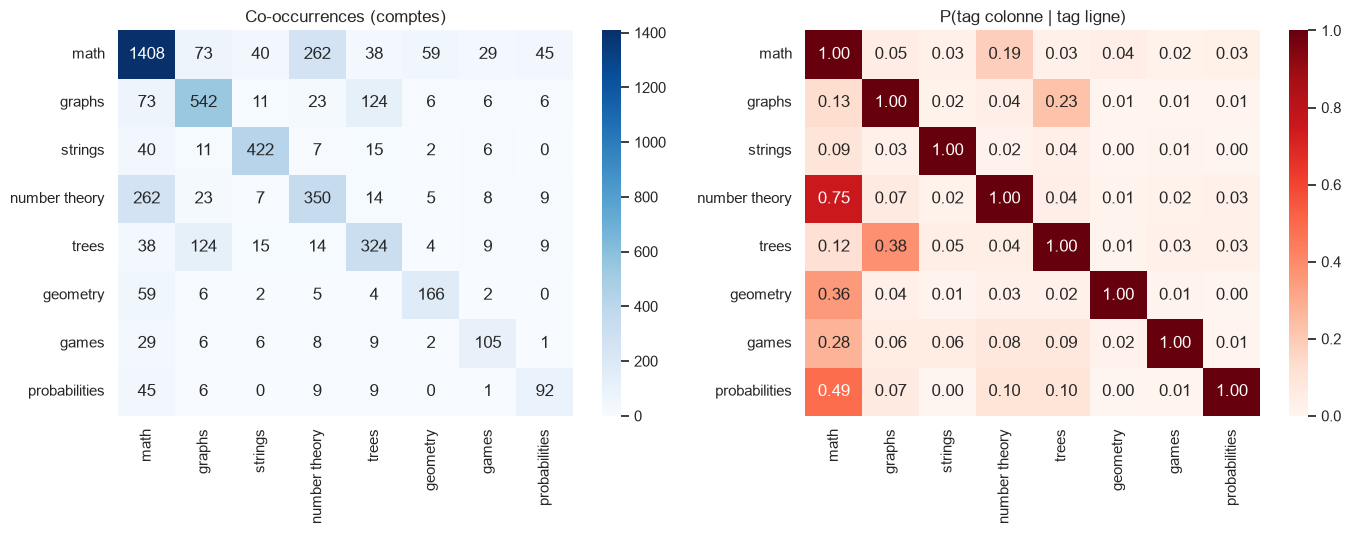

In [17]:
Y = pd.DataFrame({t: df["tags"].apply(lambda ts, t=t: t in ts) for t in TARGET_TAGS}).astype(int)
cooc = Y.T @ Y
# P(colonne | ligne) : lecture asymétrique plus parlante que les comptes bruts
cond = cooc.div(np.diag(cooc), axis=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.heatmap(cooc, annot=True, fmt="d", cmap="Blues", ax=axes[0]).set(title="Co-occurrences (comptes)")
sns.heatmap(cond, annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1, ax=axes[1]).set(title="P(tag colonne | tag ligne)")
plt.tight_layout()
plt.show()

In [18]:
labelsets = Y.apply(lambda r: tuple(t for t in TARGET_TAGS if r[t]), axis=1)
print(f"{labelsets.nunique()} combinaisons distinctes de tags cibles")
labelsets.value_counts().head(12)

58 combinaisons distinctes de tags cibles


()                       2304
(math,)                   929
(strings,)                353
(graphs,)                 332
(math, number theory)     222
(trees,)                  147
(graphs, trees)           107
(geometry,)                95
(number theory,)           69
(games,)                   60
(math, geometry)           53
(math, graphs)             46
Name: count, dtype: int64

In [19]:
# Tags "méta" ou très rares : peu exploitables comme cibles
print("'*special' :", tag_counts.get("*special", 0), "exercices")
print("Tags < 30 occurrences :", tag_counts[tag_counts < 30].to_dict())

'*special' : 58 exercices
Tags < 30 occurrences : {'2-sat': 20, 'expression parsing': 18, 'meet-in-the-middle': 17, 'fft': 16, 'chinese remainder theorem': 10, 'schedules': 4}


**Constats labels**
- 37 tags, très déséquilibrés. Les 8 cibles vont de `math` (28 %) à `probabilities` (1.8 %, 92 exemples) ⇒ métriques
  **Macro-F1 et par tag**, seuils de décision à ajuster par tag.
- 46 % des exercices n'ont **aucun** tag cible : le modèle doit savoir prédire l'ensemble vide.
- Co-occurrences fortes et attendues : `number theory → math`, `trees → graphs`, `probabilities → math`.
  À exploiter (chaînes de classifieurs) ou au moins à surveiller dans l'analyse d'erreurs.
- `*special` est un tag méta (pas une notion algorithmique), 41 exercices n'ont aucun tag.

## 4. Textes, code & métadonnées : distributions et outliers

In [20]:
lengths = pd.DataFrame(
    {
        "desc_chars": df["prob_desc_description"].str.len(),
        "desc_words": df["prob_desc_description"].str.split().str.len(),
        "code_chars": df["source_code"].str.len(),
        "code_lines": df["source_code"].str.count("\n") + 1,
        "notes_chars": df["prob_desc_notes"].fillna("").str.len(),
    }
)
lengths.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).round(0)

,desc_chars,desc_words,code_chars,code_lines,notes_chars
count,4982.0,4982.0,4982.0,4982.0,4982.0
mean,951.0,167.0,1233.0,52.0,318.0
std,453.0,80.0,2205.0,79.0,321.0
min,63.0,10.0,28.0,1.0,0.0
1%,219.0,40.0,102.0,4.0,0.0
25%,626.0,110.0,364.0,18.0,0.0
50%,874.0,155.0,687.0,33.0,259.0
75%,1198.0,211.0,1320.0,59.0,476.0
99%,2389.0,416.0,9140.0,347.0,1330.0
max,3796.0,684.0,58387.0,2042.0,2881.0


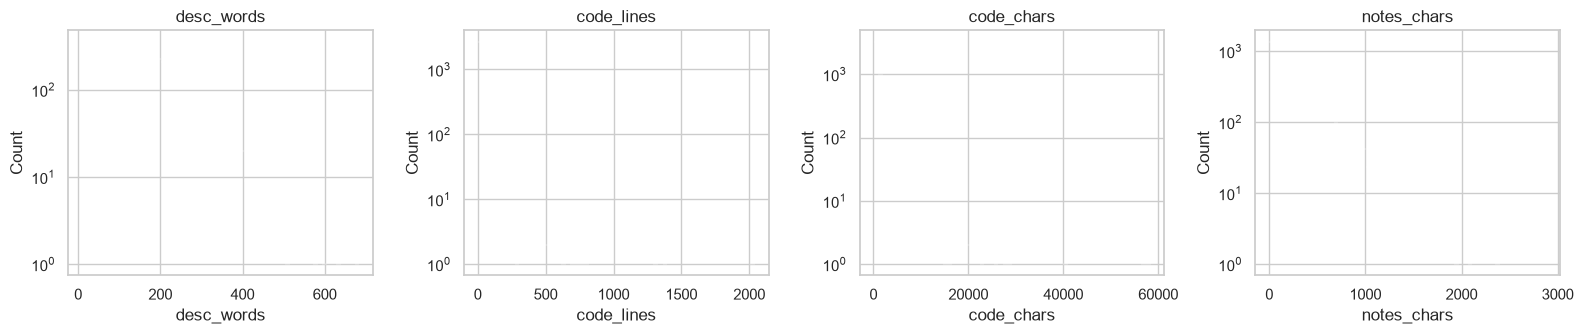

In [21]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, ["desc_words", "code_lines", "code_chars", "notes_chars"]):
    sns.histplot(lengths[col], bins=60, log_scale=(False, True), ax=ax).set(title=col)
plt.tight_layout()
plt.show()

In [22]:
def iqr_outliers(s: pd.Series, k: float = 3.0) -> pd.Series:
    """Masque des valeurs hors [Q1 - k·IQR, Q3 + k·IQR] (k=3 : outliers extrêmes)."""
    q1, q3 = s.quantile([0.25, 0.75])
    return (s < q1 - k * (q3 - q1)) | (s > q3 + k * (q3 - q1))


outliers = lengths.apply(iqr_outliers)
outliers.sum().rename("n_outliers_extremes")

desc_chars      12
desc_words      12
code_chars     212
code_lines     149
notes_chars      5
Name: n_outliers_extremes, dtype: int64

In [23]:
print("Descriptions les plus courtes :")
for k in lengths["desc_chars"].nsmallest(3).index:
    print(f"  [{k}] {df.at[k, 'tags']} -> {df.at[k, 'prob_desc_description'][:150]!r}")

print("\nCodes les plus longs (lignes) :")
for k in lengths["code_lines"].nlargest(3).index:
    print(f"  [{k}] {lengths.at[k, 'code_lines']} lignes, {df.at[k, 'tags']}")
    print("   ", df.at[k, "source_code"][:200].replace("\n", " | "))

Descriptions les plus courtes :
  [647] ['geometry'] -> 'You are given two circles. Find the area of their intersection.'
  [1260] ['implementation'] -> 'You are given two integers $$$a$$$ and $$$b$$$. Print $$$a+b$$$.'
  [853] ['binary search', 'implementation'] -> 'The term of this problem is the same as the previous one, the only exception — increased restrictions.'

Codes les plus longs (lignes) :
  [4148] 2042 lignes, ['combinatorics', 'data structures', 'dp', 'math']
 | from itertools import cha
  [2546] 1544 lignes, ['data structures', 'trees']
    # pylint: disable=redefined-builtin, ungrouped-imports | from __future__ import print_function | from bisect import bisect_left, bisect_right, insort | from collections import Sequence, MutableSequence | from
  [3542] 1539 lignes, ['geometry', 'sortings', 'brute force', 'math']
    """ | #include <bits/stdc++.h> | #ifdef DEMETRIO | #define deb(...) fprintf(stderr,__VA_ARGS__) | #define deb1(x) cerr << #x << " = " << x << endl | #else 

In [24]:
# Bruit textuel : notation LaTeX Codeforces ($$$) et textes non anglais
print(f"Descriptions avec LaTeX '$$$' : {df['prob_desc_description'].str.contains('$$$', regex=False).mean():.0%}")
cyrillic = df["prob_desc_description"].str.contains("[а-яА-Я]", regex=True)
print(f"Descriptions avec caractères cyrilliques : {cyrillic.sum()}")
df.loc[cyrillic, "prob_desc_description"].str[:120].head(3)

Descriptions avec LaTeX '$$$' : 56%
Descriptions avec caractères cyrilliques : 31


sample_id
266    Little Susie, thanks to her older brother, likes to play with cars. Today she decided to set up a tournament between...
293    Yaroslav likes algorithms. We'll describe one of his favorite algorithms.  The algorithm receives a string as the in...
345    We know that prime numbers are positive integers that have exactly two distinct positive divisors. Similarly, we'll ...
Name: prob_desc_description, dtype: object

In [25]:
# Taille du code : longueur moyenne par tag cible (le code geometry/graphs est-il plus long ?)
long_by_tag = pd.DataFrame(
    {t: lengths.loc[Y[t] == 1, ["desc_words", "code_lines"]].median() for t in TARGET_TAGS}
).T.sort_values("code_lines")
long_by_tag.loc["(tous)"] = lengths[["desc_words", "code_lines"]].median()
long_by_tag

,desc_words,code_lines
math,139.5,27.0
games,181.0,28.0
strings,148.0,30.0
geometry,146.5,34.0
number theory,120.0,38.0
probabilities,186.0,41.0
graphs,166.0,55.0
trees,168.0,61.0
(tous),155.0,33.0


### Métadonnées : difficulté, date, limites

difficulty == -1 : 15 | NaN : 39


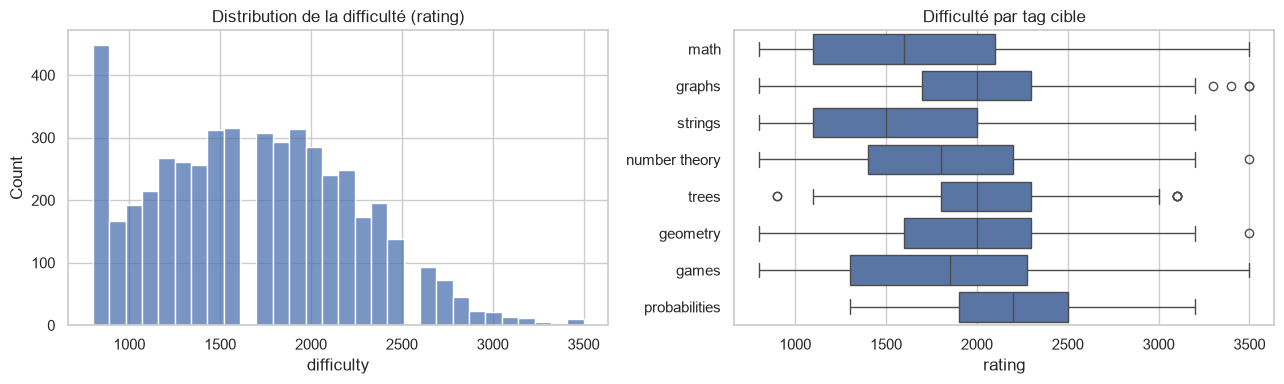

In [26]:
print("difficulty == -1 :", (df["difficulty"] == -1).sum(), "| NaN :", df["difficulty"].isna().sum())

diff = df["difficulty"].where(df["difficulty"] > 0)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(diff, bins=30, ax=axes[0]).set(title="Distribution de la difficulté (rating)")
sns.boxplot(
    data=pd.concat([diff[Y[t] == 1].rename(t) for t in TARGET_TAGS], axis=1).melt().dropna(),
    x="value", y="variable", ax=axes[1],
).set(title="Difficulté par tag cible", xlabel="rating", ylabel="")
plt.tight_layout()
plt.show()

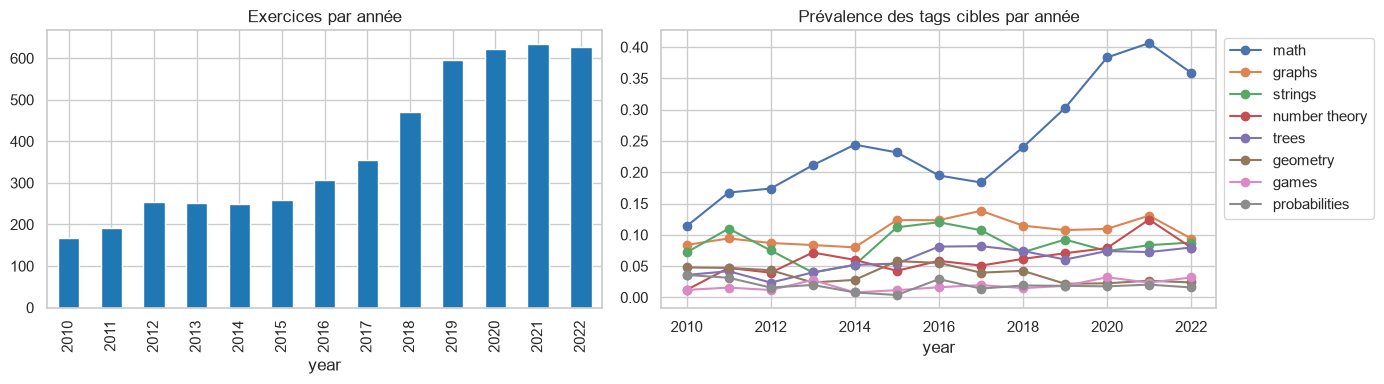

In [27]:
df["year"] = pd.to_datetime(df["prob_desc_created_at"].astype(int), unit="s").dt.year
prevalence_by_year = Y.groupby(df["year"]).mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df["year"].value_counts().sort_index().plot.bar(ax=axes[0], color="tab:blue", title="Exercices par année")
prevalence_by_year.plot(ax=axes[1], marker="o", title="Prévalence des tags cibles par année")
axes[1].legend(bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

In [28]:
def parse_limit(s: pd.Series) -> pd.Series:
    """Extrait la valeur numérique d'une limite ('2 seconds', '256 мегабайт')."""
    return s.str.extract(r"([\d.]+)")[0].astype(float)


limits = pd.DataFrame(
    {"time_s": parse_limit(df["prob_desc_time_limit"]), "memory_mb": parse_limit(df["prob_desc_memory_limit"])}
)
print(limits.describe().round(1))
print("\nLimites mémoire rares (< 10 exercices) :", limits["memory_mb"].value_counts().loc[lambda s: s < 10].to_dict())

       time_s  memory_mb
count  4982.0     4982.0
mean      1.8      273.8
std       1.0       81.8
min       0.5       16.0
25%       1.0      256.0
50%       2.0      256.0
75%       2.0      256.0
max      15.0     1024.0

Limites mémoire rares (< 10 exercices) : {128.0: 9, 265.0: 2, 32.0: 2, 384.0: 1, 16.0: 1, 768.0: 1, 28.0: 1, 70.0: 1, 216.0: 1}


**Constats distributions / outliers**
- Descriptions bien bornées (10 à 684 mots). Le code a une **queue très lourde** (médiane 33 lignes, max 2 042) : les plus longs
  embarquent des bibliothèques copiées-collées (SortedList…) voire du C++ dans une docstring ⇒ troncature et retrait du
  boilerplate côté features.
- Les outliers ne sont pas des erreurs : on **les garde** (exercices valides), mais on borne les longueurs côté features.
- Le code des tags `graphs` / `trees` est nettement plus long (médiane ~60 lignes vs 33) : la longueur du code est une feature candidate.
- LaTeX `$$$` dans 56 % des descriptions → nettoyage à prévoir. 31 descriptions contiennent du cyrillique : 17 entièrement
  en russe, les autres sont des **homoglyphes** isolés (`А`, `С` cyrilliques dans un texte anglais) → normalisation Unicode.
- `difficulty` : 15 valeurs `-1` (sentinelle) + 39 NaN → à traiter comme manquantes. Difficulté médiane : `probabilities` 2200,
  `graphs` / `trees` / `geometry` 2000 vs `strings` 1500, `math` 1600 ⇒ feature potentiellement utile.
- Données de 2010 à 2022, plus récentes en majorité. **Dérive** nette sur `math` (11 % en 2010 → ~40 % en 2021) : les
  pratiques d'annotation évoluent ; un split aléatoire groupé reste pertinent, mais la date est une feature candidate.

## 5. Synthèse & décisions pour la suite

| Point | Décision |
|---|---|
| Colonnes constantes (`lang_cluster`, `exec_outcome`, `hidden_unit_tests`) | Supprimées |
| Quasi-doublons de descriptions (versions easy/hard, labels parfois divergents) | Split **groupé** par `dup_group` + stratifié multi-label, seed fixe |
| Dérive temporelle de `math` | Date/difficulté comme features candidates, à valider par gain mesuré |
| 8 tags cibles très déséquilibrés (2 % à 28 %) | Macro-F1 + F1 par tag, seuils optimisés par tag sur la validation |
| Majorité d'exercices sans tag cible | Conserver ces exemples (négatifs utiles), ne pas filtrer |
| LaTeX `$$$`, homoglyphes cyrilliques, métadonnées en russe | Nettoyage texte / normalisation Unicode dans `src/features.py` |
| Code Python 2 & 3, boilerplate fast-IO | Features lexicales plutôt qu'`ast`, retrait du boilerplate |
| `difficulty == -1` | Considéré comme valeur manquante |
| Outliers de longueur | Conservés, longueurs bornées/tronquées côté features |